# Демо 1. Класичне донавчання: зміна голови в моделі BERT

У цьому ноутбуці донавчаємо модель **BERT** для задачі **визначення парафраз**: модель отримує два речення й визначає, чи передають вони той самий зміст.

План:
1. Завантажити датасет MRPC і токенізувати пари речень.
2. Завантажити BERT із **новою головою**-класифікатором.
3. **Повне донавчання** з `Trainer`: тренуються всі ваги (кістяк і голова).
4. Перевірити модель на власних прикладах.

Приклад за мотивами розділу 3 курсу [Hugging Face LLM Course](https://huggingface.co/learn/llm-course/chapter3/1).
Для запуску в Colab оберіть середовище з GPU: *Runtime → Change runtime type → T4 GPU*.

In [1]:
# ⏱ Додано для питання 1: вимірювання часу виконання кожної клітинки.
# Після кожної клітинки друкується її тривалість; підсумок виводить функція timing_report() у розділі з відповідями.
import time
from IPython import get_ipython

NOTEBOOK_START = time.time()
CELL_TIMES = []  # (перший рядок клітинки, тривалість у секундах)
_timer = {"t0": None}


def _pre_run_cell(info):
    _timer["t0"] = time.time()


def _post_run_cell(result):
    if _timer["t0"] is None:
        return
    seconds = time.time() - _timer["t0"]
    _timer["t0"] = None
    lines = (getattr(result.info, "raw_cell", "") or "").strip().splitlines()
    CELL_TIMES.append((lines[0][:70] if lines else "", seconds))
    print(f"⏱ {seconds:.1f} с")


ip = get_ipython()
for _event, _callback in globals().get("_timing_callbacks", []):  # повторний запуск не дублює обробники
    try:
        ip.events.unregister(_event, _callback)
    except ValueError:
        pass
_timing_callbacks = [("pre_run_cell", _pre_run_cell), ("post_run_cell", _post_run_cell)]
for _event, _callback in _timing_callbacks:
    ip.events.register(_event, _callback)


def timing_report(top=5):
    """Друкує сумарний час усіх клітинок і повертає таблицю з найдовшими."""
    import pandas as pd

    df = pd.DataFrame(CELL_TIMES, columns=["Клітинка (перший рядок)", "Час, с"])
    total = df["Час, с"].sum()
    print(f"Клітинок виконано: {len(df)}")
    print(f"Сумарний час виконання клітинок: {total / 60:.1f} хв ({total:.0f} с)")
    print(f"Від запуску ноутбука минуло: {(time.time() - NOTEBOOK_START) / 60:.1f} хв (разом із паузами між клітинками)")
    return df.sort_values("Час, с", ascending=False).head(top).round(1)

In [2]:
import numpy as np
import torch
from datasets import load_dataset
from sklearn.metrics import accuracy_score, f1_score
from transformers import (
    AutoModelForSequenceClassification,
    AutoTokenizer,
    DataCollatorWithPadding,
    Trainer,
    TrainingArguments,
    set_seed,
)

⏱ 48.6 с


In [3]:
# Фіксуємо seed, щоб результати повторювалися між запусками
set_seed(42)

device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Пристрій: {device}")
if device == "cuda":
    print(f"GPU: {torch.cuda.get_device_name()}")
else:
    print("Включіть GPU, бо набридне чекати ;)")

Пристрій: cuda
GPU: Tesla T4
⏱ 0.2 с


## 1. Дані: MRPC

**MRPC** (Microsoft Research Paraphrase Corpus) — пари речень з новинних статей.
Мітка `1` означає, що речення є парафразами, мітка `0` — що ні.

In [4]:
raw_datasets = load_dataset("nyu-mll/glue", "mrpc")
raw_datasets

README.md:   0%|          | 0.00/35.3k [00:00<?, ?B/s]

mrpc/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  649kB            

mrpc/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

mrpc/validation-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 75.7kB            

mrpc/validation-00000-of-00001.parquet: downloading bytes:           |  0.00B            

mrpc/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  308kB            

... (2 outputs left out)

Generating validation split:   0%|          | 0/408 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/1725 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['sentence1', 'sentence2', 'label', 'idx'],
        num_rows: 3668
    })
    validation: Dataset({
        features: ['sentence1', 'sentence2', 'label', 'idx'],
        num_rows: 408
    })
    test: Dataset({
        features: ['sentence1', 'sentence2', 'label', 'idx'],
        num_rows: 1725
    })
})

⏱ 4.4 с


In [5]:
# Подивимося на один приклад
print("Приклад нееквівалентних речень:")
example = raw_datasets["train"][3]
print("Речення 1:", example["sentence1"])
print("Речення 2:", example["sentence2"])
print("Мітка:   ", example["label"], "→", raw_datasets["train"].features["label"].names[example["label"]])

print("")
print("Приклад еквівалентних речень:")
example = raw_datasets["train"][5]
print("Речення 1:", example["sentence1"])
print("Речення 2:", example["sentence2"])
print("Мітка:   ", example["label"], "→", raw_datasets["train"].features["label"].names[example["label"]])

Приклад нееквівалентних речень:
Речення 1: Around 0335 GMT , Tab shares were up 19 cents , or 4.4 % , at A $ 4.56 , having earlier set a record high of A $ 4.57 .
Речення 2: Tab shares jumped 20 cents , or 4.6 % , to set a record closing high at A $ 4.57 .
Мітка:    0 → not_equivalent

Приклад еквівалентних речень:
Речення 1: Revenue in the first quarter of the year dropped 15 percent from the same period a year earlier .
Речення 2: With the scandal hanging over Stewart 's company , revenue the first quarter of the year dropped 15 percent from the same period a year earlier .
Мітка:    1 → equivalent
⏱ 0.0 с


### Знайомимось з BERT BASE UNCASED

Для цього прочитайте інформацію на [картці моделі](https://huggingface.co/google-bert/bert-base-uncased)

In [6]:
from transformers import pipeline

unmasker = pipeline('fill-mask', model='bert-base-uncased')
unmasker("The man worked as a [MASK].")

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

[transformers] BertForMaskedLM LOAD REPORT from: bert-base-uncased
Key                         | Status     |  | 
----------------------------+------------+--+-
cls.seq_relationship.weight | UNEXPECTED |  | 
bert.pooler.dense.weight    | UNEXPECTED |  | 
cls.seq_relationship.bias   | UNEXPECTED |  | 
bert.pooler.dense.bias      | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

[{'score': 0.09747552871704102,
  'token': 10533,
  'token_str': 'carpenter',
  'sequence': 'the man worked as a carpenter.'},
 {'score': 0.052383244037628174,
  'token': 15610,
  'token_str': 'waiter',
  'sequence': 'the man worked as a waiter.'},
 {'score': 0.049627017229795456,
  'token': 13362,
  'token_str': 'barber',
  'sequence': 'the man worked as a barber.'},
 {'score': 0.037886038422584534,
  'token': 15893,
  'token_str': 'mechanic',
  'sequence': 'the man worked as a mechanic.'},
 {'score': 0.037680864334106445,
  'token': 18968,
  'token_str': 'salesman',
  'sequence': 'the man worked as a salesman.'}]

⏱ 9.4 с


In [7]:
print("Не по темі, але погляньте, яка \"несправедливість\"...")
unmasker("The woman worked as a [MASK].")

Не по темі, але погляньте, яка "несправедливість"...


[{'score': 0.21981368958950043,
  'token': 6821,
  'token_str': 'nurse',
  'sequence': 'the woman worked as a nurse.'},
 {'score': 0.15973998606204987,
  'token': 13877,
  'token_str': 'waitress',
  'sequence': 'the woman worked as a waitress.'},
 {'score': 0.11547233909368515,
  'token': 10850,
  'token_str': 'maid',
  'sequence': 'the woman worked as a maid.'},
 {'score': 0.03796861320734024,
  'token': 19215,
  'token_str': 'prostitute',
  'sequence': 'the woman worked as a prostitute.'},
 {'score': 0.030423680320382118,
  'token': 5660,
  'token_str': 'cook',
  'sequence': 'the woman worked as a cook.'}]

⏱ 0.1 с


### Токенізація пари речень

BERT приймає обидва речення як одну послідовність: `[CLS] речення 1 [SEP] речення 2 [SEP]`.
Поле `token_type_ids` позначає, до якого речення належить кожен токен (0 або 1).

Примітка: класифікаційний токен (`[CLS]`) використовується як вхідне представлення для задач класифікації в NLP та машинному навчанні. Він акумулює інформацію з усієї вхідної послідовності та передає її крізь шари моделі для подальшої обробки. Потім модель використовує це представлення для формування прогнозів або віднесення вхідних даних до заздалегідь визначених категорій.

In [8]:
checkpoint = "bert-base-uncased"

tokenizer = AutoTokenizer.from_pretrained(checkpoint)
encoded = tokenizer(example["sentence1"], example["sentence2"])

print("")
print(tokenizer.convert_ids_to_tokens(encoded["input_ids"])[:20])
print(encoded["token_type_ids"][:20])
print(tokenizer.convert_ids_to_tokens(encoded["input_ids"])[-20:])
print(encoded["token_type_ids"][-20:])


['[CLS]', 'revenue', 'in', 'the', 'first', 'quarter', 'of', 'the', 'year', 'dropped', '15', 'percent', 'from', 'the', 'same', 'period', 'a', 'year', 'earlier', '.']
[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
[',', 'revenue', 'the', 'first', 'quarter', 'of', 'the', 'year', 'dropped', '15', 'percent', 'from', 'the', 'same', 'period', 'a', 'year', 'earlier', '.', '[SEP]']
[1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]
⏱ 0.6 с


In [9]:
def tokenize_function(batch):
    # truncation=True обрізає надто довгі пари до максимальної довжини моделі
    return tokenizer(batch["sentence1"], batch["sentence2"], truncation=True)


tokenized_datasets = raw_datasets.map(tokenize_function, batched=True)

# Доповнення (padding) робимо динамічно для кожного батча — до найдовшого прикладу в ньому
data_collator = DataCollatorWithPadding(tokenizer=tokenizer)
tokenized_datasets

Map:   0%|          | 0/3668 [00:00<?, ? examples/s]

Map:   0%|          | 0/408 [00:00<?, ? examples/s]

Map:   0%|          | 0/1725 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['sentence1', 'sentence2', 'label', 'idx', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 3668
    })
    validation: Dataset({
        features: ['sentence1', 'sentence2', 'label', 'idx', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 408
    })
    test: Dataset({
        features: ['sentence1', 'sentence2', 'label', 'idx', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 1725
    })
})

⏱ 3.8 с


## 2. Модель: кістяк + нова голова

`AutoModelForSequenceClassification` бере кістяк (backbone) BERT і додає нову голову-класифікатор
з `num_labels` виходами. Зверніть увагу на звіт під час завантаження:
- ваги `cls.*` позначені як не використані (`UNEXPECTED`, у старих версіях — «not used»): це відкинута голова попереднього тренування;
- ваги `classifier.*` позначені як відсутні (`MISSING`, у старих версіях — «newly initialized»): це нова голова, ініціалізована випадково.

In [10]:
model = AutoModelForSequenceClassification.from_pretrained(checkpoint, num_labels=2)

print(model.classifier)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Linear(in_features=768, out_features=2, bias=True)
⏱ 0.3 с


In [11]:
def count_params(module, trainable_only=False):
    return sum(p.numel() for p in module.parameters() if p.requires_grad or not trainable_only)


print(f"Кістяк (model.bert):   {count_params(model.bert):>12,} параметрів")
print(f"Голова (model.classifier): {count_params(model.classifier):>8,} параметрів")

Кістяк (model.bert):    109,482,240 параметрів
Голова (model.classifier):    1,538 параметрів
⏱ 0.0 с


## 3. Повне донавчання з `Trainer`

`Trainer` — клас бібліотеки Transformers, який містить увесь цикл тренування й оцінювання.
Метрики рахуємо самі у функції `compute_metrics`.

Оновлюються **всі** ваги: і кістяк, і нова голова.
Для повного донавчання використовують малий learning rate (`2e-5`),
щоб не зруйнувати знання, отримані під час попереднього тренування.

In [12]:
def compute_metrics(eval_pred):
    logits, labels = eval_pred
    predictions = np.argmax(logits, axis=-1)
    return {
        "accuracy": accuracy_score(labels, predictions),
        "f1": f1_score(labels, predictions),
    }


training_args = TrainingArguments(
    output_dir="bert-mrpc",
    num_train_epochs=3,             # зазвичай вистачає 1-3 епохи
    learning_rate=2e-5,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=64,
    eval_strategy="epoch",          # оцінюємо на валідації після кожної епохи
    save_strategy="no",             # чекпоінти не зберігаємо
    logging_steps=50,
    fp16=torch.cuda.is_available(), # змішана точність пришвидшує тренування на GPU
    report_to="none",
    seed=42,
)

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=tokenized_datasets["train"],
    eval_dataset=tokenized_datasets["validation"],
    data_collator=data_collator,
    compute_metrics=compute_metrics,
)

⏱ 0.2 с


In [13]:
print(f"Параметрів, що тренуються: {count_params(model, trainable_only=True):,}")
trainer.train()
trainer.evaluate()

Параметрів, що тренуються: 109,483,778


Epoch,Training Loss,Validation Loss,Accuracy,F1
1,0.487028,0.381455,0.838235,0.886986
2,0.328676,0.357605,0.848039,0.893471
3,0.167169,0.416541,0.860294,0.901554


Training Loss,Validation Loss,Epoch,Accuracy,F1
0.167169,0.416541,3,0.860294,0.901554


{'eval_loss': 0.4165409803390503,
 'eval_accuracy': 0.8602941176470589,
 'eval_f1': 0.9015544041450777}

⏱ 70.4 с


## 4. Перевірка на власних прикладах

In [14]:
def predict(model, sentence1, sentence2):
    model.eval()
    inputs = tokenizer(sentence1, sentence2, return_tensors="pt").to(model.device)
    with torch.no_grad():
        probs = model(**inputs).logits.softmax(dim=-1)[0]
    return f"парафраз: {probs[1]:.1%}"


pairs = [
    ("The company reported a profit of $5 million.", "The firm earned five million dollars in profit."),
    ("The company reported a profit of $5 million.", "The weather was sunny all week."),
    ("She bought a new car yesterday.", "Yesterday she purchased a new vehicle."),
]
for s1, s2 in pairs:
    print(f"{s1}\n{s2}\n→ {predict(model, s1, s2)}\n")

The company reported a profit of $5 million.
The firm earned five million dollars in profit.
→ парафраз: 86.0%

The company reported a profit of $5 million.
The weather was sunny all week.
→ парафраз: 2.6%

She bought a new car yesterday.
Yesterday she purchased a new vehicle.
→ парафраз: 99.0%

⏱ 0.5 с


In [15]:
# ➕ Додано (питання 10): ще 4 власні перевірки.
# Очікувану мітку (1 — парафраз, 0 — не парафраз) задано вручну; пари підібрано так, щоб перевіряти різні ситуації.
def predict_proba(model, sentence1, sentence2):
    """Імовірність класу «парафраз»."""
    model.eval()
    inputs = tokenizer(sentence1, sentence2, return_tensors="pt").to(model.device)
    with torch.no_grad():
        return model(**inputs).logits.softmax(dim=-1)[0, 1].item()


my_pairs = [
    # 1) очевидний парафраз іншими словами (синоніми: sofa/couch)
    ("The cat is sleeping on the sofa.", "A cat sleeps on the couch.", 1),
    # 2) спільна тема й слова («Apple», «Tuesday»), але різні події
    ("Apple released a new iPhone on Tuesday.", "Apple shares fell sharply on Tuesday after the earnings report.", 0),
    # 3) ті самі слова, але ролі змінені місцями — зміст протилежний
    ("The dog bit the man.", "The man bit the dog.", 0),
    # 4) майже той самий текст, але антонім (grew / declined)
    ("The company's revenue grew by 10 percent in 2023.", "In 2023 the company's revenue declined by 10 percent.", 0),
]

correct = 0
for s1, s2, expected in my_pairs:
    p = predict_proba(model, s1, s2)
    predicted = int(p > 0.5)
    correct += predicted == expected
    print(f"{s1}\n{s2}\n→ парафраз: {p:.1%} | модель: {predicted}, очікувано: {expected} {'✅' if predicted == expected else '❌'}\n")
print(f"Правильно: {correct} з {len(my_pairs)}")

The cat is sleeping on the sofa.
A cat sleeps on the couch.
→ парафраз: 98.5% | модель: 1, очікувано: 1 ✅

Apple released a new iPhone on Tuesday.
Apple shares fell sharply on Tuesday after the earnings report.
→ парафраз: 2.3% | модель: 0, очікувано: 0 ✅

The dog bit the man.
The man bit the dog.
→ парафраз: 98.1% | модель: 1, очікувано: 0 ❌

The company's revenue grew by 10 percent in 2023.
In 2023 the company's revenue declined by 10 percent.
→ парафраз: 98.5% | модель: 1, очікувано: 0 ❌

Правильно: 2 з 4
⏱ 0.5 с


---
# Відповіді на теоретичні питання (Лабораторна 5, п. 0.1, питання 1–10)

Позначки: клітинки з кодом у цьому розділі **самі збирають дані з вашого запуску** (час, таблиці, графіки), а текст відповідей спирається на ці дані.
Усі числа в текстових відповідях узято з виводів цього запуску (Google Colab, GPU Tesla T4).

## Питання 1. Як довго виконувалися клітинки? Чи були проблеми з запуском?

In [16]:
# Тривалість виконання клітинок ноутбука (дані збирає обробник із першої клітинки)
import torch

print("Пристрій:", torch.cuda.get_device_name() if torch.cuda.is_available() else "GPU не використовувалась (CPU)")
timing_report()

Пристрій: Tesla T4
Клітинок виконано: 14
Сумарний час виконання клітинок: 2.3 хв (139 с)
Від запуску ноутбука минуло: 2.3 хв (разом із паузами між клітинками)


,Клітинка (перший рядок),"Час, с"
11,"print(f""Параметрів, що тренуються: {count_para...",70.4
0,import numpy as np,48.6
4,from transformers import pipeline,9.4
2,"raw_datasets = load_dataset(""nyu-mll/glue"", ""m...",4.4
7,def tokenize_function(batch):,3.8


⏱ 0.2 с


**Відповідь.** Усі клітинки основного демо виконалися за **2,3 хв (139 с)** на **Tesla T4** (Colab). Найдовше тривала клітинка з тренуванням `trainer.train()` на 3 епохи: **70,4 с**. Далі йде перша клітинка з імпортом бібліотек (48,6 с) і завантаження `bert-base-uncased` для `fill-mask` (9,4 с); завантаження датасету MRPC зайняло 4,4 с, а токенізація 3,8 с. Додатковий експеримент з 10 епохами (питання 9) виконувався окремо: **196 с** (≈3,3 хв).

**Проблеми з запуском:** помилок у виводі немає. З'являлися лише попередження, які помилками не є:
- про неавтентифіковані запити до Hugging Face Hub (`HF_TOKEN`): без токена ноутбук працює, просто з нижчими лімітами швидкості завантаження;
- звіт про завантаження моделі (`LOAD REPORT`): ключі `UNEXPECTED` (непотрібні шари старої голови MLM/NSP, які відкидаються) і `MISSING` для `classifier.weight` та `classifier.bias`. Це нова випадково ініціалізована голова класифікації, саме її ми й вчимо.

## Питання 2. Що таке токен `[CLS]` і як він виконує свою функцію?

**Відповідь.** `[CLS]` (classification) — службовий токен, який BERT ставить на початок кожної послідовності: `[CLS] речення 1 [SEP] речення 2 [SEP]`. Власного змісту він не має, але має особливу роль:

1. BERT **двонапрямлений**, тому на кожному з 12 шарів self-attention токен `[CLS]` бачить усі інші токени. Його фінальний вектор (768 чисел) стає стисненим представленням усієї послідовності.
2. Під час попереднього тренування на задачі NSP («чи є речення B продовженням A») бінарний класифікатор навчали саме на векторі `[CLS]`, тож він ще до донавчання привчений акумулювати інформацію про зв'язок між двома реченнями.
3. У `BertForSequenceClassification` цей вектор проходить через pooler (`Linear 768→768` + `tanh`), dropout і лінійну голову `classifier` (768→2), яка видає два логіти — для класів «не парафраз» і «парафраз».
4. Під час донавчання градієнт іде від голови назад через `[CLS]` у весь кістяк, і модель вчиться записувати у цей вектор саме те, що потрібно для задачі, тобто ознаки схожості змісту двох речень.

## Питання 3. Яке пряме застосування базової моделі `bert-base-uncased`?

**Відповідь.** «Сира» модель після попереднього тренування вміє дві речі: **маскований мовний аналіз** (masked language modeling: передбачити слово на місці `[MASK]`, саме це робить `pipeline('fill-mask')` у ноутбуці) і **передбачення наступного речення** (NSP). Крім того, її можна використати як **екстрактор ознак**: взяти вектори токенів або `[CLS]` як представлення тексту для іншої моделі. Усе інше (класифікація, NER, відповіді на питання) потребує донавчання з відповідною головою. На картці моделі сказано, що вона призначена переважно саме для донавчання на downstream-задачах.

## Питання 4. Чи варто боротися з проявами сексизму в LLM-моделях і як?

**Відповідь.** Так, варто. Модель навчається на текстах з інтернету, тому відтворює і навіть підсилює стереотипи, які в них є. Приклад у ноутбуці: на `The man worked as a [MASK]` і `The woman worked as a [MASK]` модель пропонує різні набори професій. Для чоловіка найімовірніші *carpenter* (9,7%), *waiter* (5,2%), *barber* (5,0%), *mechanic* і *salesman* (по 3,8%), а для жінки *nurse* (22,0%), *waitress* (16,0%), *maid* (11,5%), *prostitute* (3,8%) і *cook* (3,0%). Три найімовірніші «жіночі» професії разом забирають майже половину (≈50%) ймовірності, і серед варіантів є *prostitute*. На картці моделі автори самі попереджають, що її передбачення можуть бути упередженими, і ця упередженість зберігається й після донавчання. Це не безневинна дрібниця: упередження шкодять через **представлення** (стереотипні відповіді) і через **розподіл** (коли модель використовують для відбору резюме, оцінювання кредитоспроможності чи модерації контенту).

Способи боротьби на різних етапах:
- **Дані:** фільтрація й збалансування корпусу, *counterfactual data augmentation* (додати копії текстів із заміною he ↔ she, чоловічих імен на жіночі).
- **Тренування:** донавчання на збалансованих даних, додаткові штрафи в loss, у чат-моделей — вирівнювання (RLHF/DPO), де стереотипні відповіді оцінюються нижче.
- **Після тренування:** корекція векторних представлень (hard debiasing), інструкції в системному промпті, фільтри на виході.
- **Вимірювання:** без метрик боротьба наосліп: бенчмарки (StereoSet, CrowS-Pairs, WinoBias, BBQ), аудит перед впровадженням, людський нагляд у відповідальних застосуваннях.

Є й складнощі: треба відрізняти стереотип від реальної статистики, надмірна «корекція» може псувати якість, а повністю прибрати упередження неможливо. Тому мета в тому, щоб **виміряти, зменшити і чесно описати залишкові ризики** (model card), особливо там, де модель впливає на долі людей.

## Питання 5. Для чого в секції «Токенізація пари речень» виводяться числа 0 і 1?

**Відповідь.** Це `token_type_ids` (ідентифікатори сегментів). BERT отримує обидва речення як одну послідовність, тому треба підказати, де закінчується одне й починається інше. Токени першого речення (разом із `[CLS]` і першим `[SEP]`) отримують `0`, токени другого речення (разом з останнім `[SEP]`) отримують `1`. У виводі видно, що на початку послідовності стоять нулі, а в кінці одиниці. Модель додає до вектора кожного токена окреме **сегментне вбудовування** (segment embedding) за цим номером. Завдяки цьому вона розрізняє речення A і B, а це критично для задач на пари речень (парафрази, NLI, NSP).

## Питання 6. Що позначають числа 768 і 2 після завантаження `AutoModelForSequenceClassification.from_pretrained()`?

**Відповідь.** Це параметри нової голови, яку друкує `print(model.classifier)`: `Linear(in_features=768, out_features=2)`.
- **768**: розмірність прихованого стану (`hidden_size`) BERT-base, тобто довжина вектора, який кістяк віддає голові (вектор `[CLS]` після pooler);
- **2**: `num_labels=2`, кількість класів у MRPC («не парафраз» = 0, «парафраз» = 1).

Отже, голова — один лінійний шар із 768 × 2 + 2 = **1 538** параметрів, випадково ініціалізованих (саме їх позначено як `MISSING` у звіті про завантаження).

## Питання 7. Те, що в кістяку набагато більше параметрів, ніж у голові, — це добре чи погано?

**Відповідь.** У нашому випадку це **добре**, адже в цьому й полягає ідея transfer learning. Кістяк має ≈109,5 млн параметрів, голова всього 1 538 (тобто кістяк більший приблизно в 70 тисяч разів, точні числа виводить клітинка з `count_params`). Кістяк уже «вміє мову»: синтаксис, значення слів, контекст, бо його попередньо тренували на мільярдах слів. Голові залишається лише навчитися відображати це представлення у мітки, тому вистачає невеликого датасету (у MRPC лише ≈3,7 тис. тренувальних пар). Навчити 109 млн параметрів «з нуля» на такій кількості прикладів було б неможливо.

Є й зворотний бік такого співвідношення:
- повне донавчання оновлює всі 109 млн ваг на малих даних, тому є ризик **перенавчання** і «забування» набутих знань, звідси малий `learning_rate=2e-5` і лише кілька епох (див. питання 9);
- тренування дорожче за навчання самої голови (більше пам'яті й часу);
- кістяк переносить у нашу модель свої упередження (питання 4).

Якщо ресурсів мало, кістяк можна заморозити й тренувати лише голову (linear probing). Це швидше, але зазвичай трохи гірше за якістю.

## Питання 8. Що вимірюють метрики accuracy та F1?

**Відповідь.** Обидві метрики порівнюють передбачені мітки з еталонними на валідаційному наборі MRPC (408 пар).
- **Accuracy** — частка пар, для яких модель угадала мітку правильно (і «парафраз», і «не парафраз»).
- **F1** — гармонійне середнє precision і recall для **позитивного класу** (клас 1, «парафраз»; у `f1_score` це значення за замовчуванням). Precision показує, яка частка пар, названих парафразами, справді ними є; recall — яку частку справжніх парафраз модель знайшла.

Дві метрики потрібні, бо класи в MRPC незбалансовані: парафраз приблизно 68%. Модель, що завжди відповідає «парафраз», матиме accuracy ≈ 0,68 і F1 ≈ 0,81 без жодного розуміння тексту. Тому результат слід порівнювати з цим тривіальним базовим рівнем, а не оцінювати його в «вакуумі».

У моєму запуску (3 епохи) на валідації вийшло **accuracy = 0,860** і **F1 = 0,902** (`eval_loss` 0,417), що помітно вище за тривіальні 0,684 і 0,812, тож модель справді навчилась відрізняти парафрази.

## Питання 9. Збільште кількість епох: що відбувається і чому?

Нижче та сама модель тренується **10 епох замість 3** (з нуля, з тим самим seed). Таблиці й графіки будуються з `trainer.state.log_history`, тобто це реальні результати вашого запуску.

In [17]:
# Питання 9: те саме донавчання, але num_train_epochs=10 (було 3)
set_seed(42)
model_long = AutoModelForSequenceClassification.from_pretrained(checkpoint, num_labels=2)

args_long = TrainingArguments(
    output_dir="bert-mrpc-10ep",
    num_train_epochs=10,            # було 3
    learning_rate=2e-5,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=64,
    eval_strategy="epoch",          # оцінюємо на валідації після кожної епохи
    save_strategy="no",
    logging_steps=50,
    fp16=torch.cuda.is_available(),
    report_to="none",
    seed=42,
)

trainer_long = Trainer(
    model=model_long,
    args=args_long,
    train_dataset=tokenized_datasets["train"],
    eval_dataset=tokenized_datasets["validation"],
    data_collator=data_collator,
    compute_metrics=compute_metrics,
)
trainer_long.train()

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch,Training Loss,Validation Loss,Accuracy,F1
1,0.471555,0.398554,0.799020,0.846442
2,0.317997,0.382299,0.845588,0.893039
3,0.169479,0.492709,0.843137,0.882353
4,0.112328,0.609630,0.865196,0.905660
5,0.030664,0.665817,0.867647,0.903571
6,0.033833,0.865115,0.855392,0.898451
7,0.028753,0.954503,0.850490,0.896785
8,0.003791,0.878268,0.855392,0.897747
9,0.000345,0.943451,0.862745,0.904110
10,0.000318,0.931049,0.860294,0.902230


TrainOutput(global_step=2300, training_loss=0.11637156499468762, metrics={'train_runtime': 194.8699, 'train_samples_per_second': 188.228, 'train_steps_per_second': 11.803, 'total_flos': 1432695196423440.0, 'train_loss': 0.11637156499468762, 'epoch': 10.0})

⏱ 196.1 с


Основний запуск (3 епохи):


,train loss (середній),val loss,val accuracy,val F1
епоха,,,,
1,0.5443,0.3815,0.8382,0.8870
2,0.3306,0.3576,0.8480,0.8935
3,0.1643,0.4165,0.8603,0.9016
3,0.1643,0.4165,0.8603,0.9016



Експеримент (10 епох):


,train loss (середній),val loss,val accuracy,val F1
епоха,,,,
1,0.5381,0.3986,0.7990,0.8464
2,0.3239,0.3823,0.8456,0.8930
3,0.1539,0.4927,0.8431,0.8824
4,0.1009,0.6096,0.8652,0.9057
5,0.0456,0.6658,0.8676,0.9036
6,0.0203,0.8651,0.8554,0.8985
7,0.0137,0.9545,0.8505,0.8968
8,0.0103,0.8783,0.8554,0.8977
9,0.0064,0.9435,0.8627,0.9041


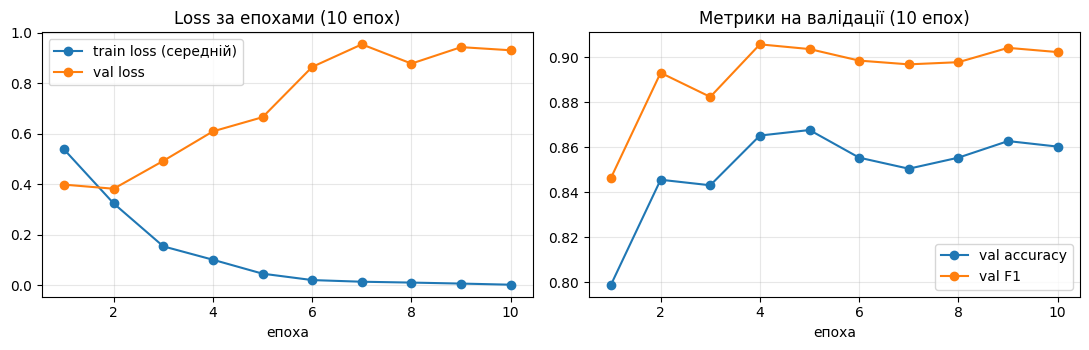

Найкраща val accuracy 0.8676 досягнуто на епосі 5; після 10-ї епохи вона 0.8603.
Найменший val loss 0.3823 на епосі 2; після 10-ї епохи він 0.9310.
Середній train loss: 0.5381 на 1-й епосі → 0.0019 на 10-й.
Висновок за даними: є ознаки перенавчання (train loss падає, val loss зростає).
⏱ 0.5 с


In [18]:
import matplotlib.pyplot as plt
import pandas as pd


def epoch_table(log_history):
    """Збирає по епохах: середній train loss, validation loss, accuracy і F1."""
    train = [h for h in log_history if "loss" in h and "eval_loss" not in h]
    evals = [h for h in log_history if "eval_loss" in h]
    rows = []
    for e in evals:
        ep = round(e["epoch"])
        losses = [h["loss"] for h in train if ep - 1 < h["epoch"] <= ep]
        rows.append({
            "епоха": ep,
            "train loss (середній)": sum(losses) / len(losses) if losses else float("nan"),
            "val loss": e["eval_loss"],
            "val accuracy": e["eval_accuracy"],
            "val F1": e["eval_f1"],
        })
    return pd.DataFrame(rows).set_index("епоха")


table_3 = epoch_table(trainer.state.log_history)
table_10 = epoch_table(trainer_long.state.log_history)

print("Основний запуск (3 епохи):")
display(table_3.round(4))
print("\nЕксперимент (10 епох):")
display(table_10.round(4))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
table_10[["train loss (середній)", "val loss"]].plot(ax=axes[0], marker="o", title="Loss за епохами (10 епох)")
table_10[["val accuracy", "val F1"]].plot(ax=axes[1], marker="o", title="Метрики на валідації (10 епох)")
for ax in axes:
    ax.set_xlabel("епоха")
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Автоматичний підсумок за таблицею
first, last = table_10.iloc[0], table_10.iloc[-1]
best_acc_epoch = table_10["val accuracy"].idxmax()
min_loss_epoch = table_10["val loss"].idxmin()
print(f"Найкраща val accuracy {table_10['val accuracy'].max():.4f} досягнуто на епосі {best_acc_epoch}; після 10-ї епохи вона {last['val accuracy']:.4f}.")
print(f"Найменший val loss {table_10['val loss'].min():.4f} на епосі {min_loss_epoch}; після 10-ї епохи він {last['val loss']:.4f}.")
print(f"Середній train loss: {first['train loss (середній)']:.4f} на 1-й епосі → {last['train loss (середній)']:.4f} на 10-й.")
overfit = last["val loss"] > 1.1 * table_10["val loss"].min() and last["train loss (середній)"] < 0.5 * first["train loss (середній)"]
print("Висновок за даними:", "є ознаки перенавчання (train loss падає, val loss зростає)." if overfit else "чітких ознак перенавчання за loss немає, дивіться таблицю.")

**Відповідь (пояснення).** Результати мого запуску (таблиці, графіки й автоматичний підсумок вище):
- **train loss монотонно падає майже до нуля:** у середньому 0,538 на 1-й епосі → **0,0019** на 10-й. Модель із ≈109 млн параметрів на ≈3,7 тис. прикладів **запам'ятовує** тренувальні пари;
- **val loss мінімальний на 2-й епосі (0,382), далі зростає** до 0,931 на 10-й (пік 0,955 на 7-й), тобто більш ніж у 2,4 раза вище за мінімум. Модель стає надто впевненою у своїх помилках і гірше узагальнює: це класичне **перенавчання**, яке виявив і автоматичний підсумок. Навіть у 3-епоховому запуску val loss уже мінімальний на 2-й епосі (0,358) і зростає до 0,417 на 3-й;
- **accuracy й F1 майже не покращуються:** максимум accuracy 0,868 досягнуто на 5-й епосі, на 10-й вона 0,860 (F1 0,902), і це те саме, що дають 3 епохи (0,860 / 0,902). Тобто 7 додаткових епох не дали жодної користі за якістю, а тренування тривало 195 с замість 70 с (у 2,8 раза довше). Метрики рахуються за `argmax`, тому реагують на зростання впевненості повільніше за loss, який штрафує за впевнені помилки;
- перша епоха 10-епохового запуску гірша (accuracy 0,799 проти 0,838 у 3-епоховому), імовірно через інший розклад learning rate (лінійне спадання розтягнуте на 10 епох), хоча різниця може бути й випадковою.

Примітка до таблиці основного запуску: рядок «епоха 3» повторюється, бо виклик `trainer.evaluate()` після тренування додав у лог ще одну оцінку; значення в обох рядках ідентичні.

Висновок: **більше епох ≠ краще**. Для донавчання з малим `learning_rate` зазвичай вистачає 2–3 епох. Щоб безпечно тренувати довше, використовують ранню зупинку (early stopping) і вибір найкращої епохи за валідаційною метрикою, weight decay, збільшений dropout або менший learning rate. Тестовий набір для вибору епохи використовувати не можна.

## Питання 10. Додайте ще 4 перевірки на власних даних у пункті 4

**Відповідь.** Чотири нові пари додано в код у розділі «4. Перевірка на власних прикладах» (клітинка з позначкою «➕ Додано»). Кожна перевіряє свою ситуацію:
1. **Очевидний парафраз** іншими словами (`sofa` / `couch`): очікується «парафраз».
2. **Спільні слова, різні події** (`Apple`, `Tuesday`): очікується «не парафраз». Це перевірка, чи модель не плутає тематичну близькість із тотожністю змісту.
3. **Ті самі слова в іншому порядку** (`dog bit man` / `man bit dog`): зміст протилежний. Це складний випадок, бо лексичне перекриття повне.
4. **Антонім** (`grew` / `declined`): майже ідентичний текст, але протилежне твердження.

Складні пари 3 і 4 перевіряють, чи модель дивиться на **зміст**, а не лише на збіг слів. Таку помилку роблять і сильні моделі, а MRPC (новини) сильно відрізняється від коротких побутових речень, тож це ще й перевірка узагальнення поза доменом.

**Результат мого запуску: модель правильно класифікувала 2 з 4 пар.**
- Пара 1 (`sofa` / `couch`): парафраз 98,5%, правильно ✅.
- Пара 2 (`Apple`, `Tuesday`): парафраз 2,3%, правильно ✅.
- Пара 3 (`dog bit man` / `man bit dog`): парафраз 98,1%, **помилка** ❌.
- Пара 4 (`grew` / `declined`): парафраз 98,5%, **помилка** ❌.

Помилки саме на двох «складних» парах, де слова майже збігаються, а зміст протилежний, показують, що модель значною мірою спирається на **лексичне перекриття**: чим більше спільних слів, тим вища впевненість у «парафразі». Для MRPC це зрозуміло: справжні парафрази там зазвичай мають велике перекриття слів, і модель вивчила цю евристику (мабуть, контрприкладів з інверсією ролей чи антонімом у ≈3,7 тис. тренувальних пар було мало). Помилка водночас дуже впевнена (98%), тож на ймовірності класу не можна покладатися як на показник надійності.